### **WADI A1 (9 Oct 2017) — EDA and cleaning**

Reads the raw WADI **A1** release, fixes its quirks, explores it and writes clean CSVs in **the same format as the A2 (2019) and SWaT 2015 cleaners**, so every modelling notebook can read the three datasets the same way.

#### Why A1 matters, and what it is (and is not)
- **A1 is the release most published WADI results use** (GDN, USAD, TranAD, Anomaly Transformer, …). Running our baselines on it is how we anchor our implementations to the literature.
- **A1 is *not* an independent plant or attack campaign.** A2 (2019) was produced from A1. The checks in §8 make this explicit:
  - the **attack file** holds the same 9–11 Oct 2017 sensor values as A2 (A2 adds a label column);
  - the **normal file** is A2's normal file **plus two spans A2 removed**: 29 Sep 15:20 → 2 Oct 16:40 (≈ 73 h) and 7 Oct 21:16 → 9 Oct 18:00 (≈ 45 h);
  - A1 has **no label column**. Labels must be built from the official attack table (`attack_description.xlsx`), which is what the literature does.
- Consequence for the paper: A1 is a **literature anchor**, not a third dataset. It cannot add statistical power to the WADI A2 results.

**Input folder:** `scada-data/WaDI/WaDi/WaDi.A1_9-Oct-2017/WADI.A1_9 Oct 2017/`

| File | Used as |
|---|---|
| `WADI_14days.csv` | 14 days of normal operation (25 Sep 18:00 → 9 Oct 18:00), 1 Hz, 4 junk lines above the header |
| `WADI_attackdata.csv` | 2 days with attacks (9 Oct 18:00 → 11 Oct 18:00), 1 Hz, **no labels** |
| `attack_description.xlsx` | official attack table → labels (transcribed in §7 and cross-checked against the file) |
| `table_WADI.pdf` | tag list |

**Cleaning applied**
1. Detect the real header row (the normal file has 4 metadata lines above it).
2. Strip the `\\WIN-25J4RO10SBF\LOG_DATA\SUTD_WADI\LOG_DATA\` server prefix from tag names.
3. Parse `Date` + `Time` (unlike A2, A1 keeps the full `h:mm:ss.fff AM/PM`) and **verify every row against the 1 Hz `Row` counter**.
4. Drop the last normal row: it has the same timestamp (9 Oct 18:00:00) as the first attack row.
5. Build `is_attack`, `attack_id` and `segment_id` from the official attack table.
6. Drop entirely empty columns, forward-fill short gaps (`FFILL_LIMIT`), flag rows still missing values (`has_missing`).
7. Number the contiguous recording blocks (`block_id`), flag the first 6 h (`is_warmup`), and flag the rows A2 removed (`a2_removed`), so later notebooks can run either the literature protocol (all 14 days) or an A2-like protocol.

**Outputs** in `WaDi.A1_9-Oct-2017/clean/`: `wadi2017_normal_clean.csv`, `wadi2017_attack_clean.csv`, `wadi2017_label_segments.csv`, `wadi2017_attack_list_clean.csv`, `wadi2017_metadata.json`. Figures: `output-figures/<name>_wadi2017.png` at 600 dpi.

In [1]:
import csv
import json
import re
import time
import zipfile
import xml.etree.ElementTree as ET
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy.stats import ks_2samp

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

RAW_DIR = Path("./scada-data/WaDI/WaDi/WaDi.A1_9-Oct-2017/WADI.A1_9 Oct 2017")
OUT_DIR = RAW_DIR.parent / "clean"
A2_CLEAN_DIR = Path("./scada-data/WaDI/WaDi/WADI.A2_19-Nov-2019/clean")   # for the A1 vs. A2 comparison (§8), optional
FIG_DIR = Path("output-figures")
FIG_VERSION = "wadi2017"
FIG_DPI = 600
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

WARMUP_SECONDS = 21_600        # first 6 h of the normal file (same convention as SWaT 2015 and WADI A2)
FFILL_LIMIT = 5                # forward-fill gaps of up to 5 s; longer gaps stay NaN and are flagged
MAX_DISCRETE_LEVELS = 5        # whole-number tags with at most this many levels count as discrete
RANDOM_STATE = 42

# A2 removed these two spans of the A1 normal file (verified in §8 when the A2 clean files are present).
A2_REMOVED_SPANS = [("2017-09-29 15:19:59", "2017-10-02 16:39:58"),
                    ("2017-10-07 21:16:11", "2017-10-09 18:00:00")]

# Paper figure style: one family, small type, recessive grid.
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": FIG_DPI, "font.family": "DejaVu Sans", "font.size": 8.5,
    "axes.titlesize": 9.5, "axes.labelsize": 8.5, "legend.fontsize": 7.5, "xtick.labelsize": 7.5,
    "ytick.labelsize": 7.5, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "axes.edgecolor": "#52514e", "axes.titleweight": "bold",
})
INK, MUTED = "#0b0b0b", "#52514e"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]   # validated categorical order
ATTACK_SHADE, REMOVED_SHADE = "#e34948", "#8d8c86"


def save_fig(fig, name):
    path = FIG_DIR / f"{name}_{FIG_VERSION}.png"
    fig.savefig(path, dpi=FIG_DPI, bbox_inches="tight")
    print(f"figure saved: {path}")


print("Raw folder exists:", RAW_DIR.exists(), "->", RAW_DIR.resolve())
print("A2 clean folder present (for §8):", A2_CLEAN_DIR.exists())

Raw folder exists: True -> /home/jaume/_DEVELOPMENT/_projects/tabular-IDS/scada-data/WaDI/WaDi/WaDi.A1_9-Oct-2017/WADI.A1_9 Oct 2017
A2 clean folder present (for §8): True


## 1. Locate the files

In [2]:
files = sorted(p for p in RAW_DIR.iterdir() if p.is_file())
for f in files:
    print(f"  {f.name:28s} {f.stat().st_size / 1e6:8.1f} MB")
NORMAL_FILE = RAW_DIR / "WADI_14days.csv"
ATTACK_FILE = RAW_DIR / "WADI_attackdata.csv"
ATTACK_TABLE_FILE = RAW_DIR / "attack_description.xlsx"
assert NORMAL_FILE.exists() and ATTACK_FILE.exists(), "Normal/attack files not found - check RAW_DIR"

  WADI_14days.csv                 777.5 MB
  WADI_attackdata.csv             111.2 MB
  attack_description.xlsx           0.0 MB
  desktop.ini                       0.0 MB
  table_WADI.pdf                    0.0 MB


## 2. Read the raw files

The header row is the first line with a `Date` cell. The normal file has four metadata lines above it (`Created: …`, `Number of rows: 1.2096E+6`, `Interpolation interval: 1 seconds`, blank).

In [3]:
def find_header_row(path, keyword="date", max_rows=15):
    # Scan raw lines: junk lines above the header may have a different number of fields.
    with open(path, newline="", encoding="utf-8", errors="replace") as f:
        for i, line in zip(range(max_rows), csv.reader(f)):
            if any(v.strip().lower() == keyword for v in line):
                return i
    raise ValueError(f"No header row with a '{keyword}' cell in {path.name}")


def read_raw(path):
    t0 = time.time()
    h = find_header_row(path)
    with open(path, encoding="utf-8", errors="replace") as f:
        preamble = [next(f).strip() for _ in range(h)]
    df = pd.read_csv(path, skiprows=h, header=0, low_memory=False)
    print(f"{path.name}: header row {h}, shape {df.shape}, read in {time.time() - t0:.0f} s")
    for line in preamble:
        if line:
            print("   preamble:", line[:100])
    return df


raw_normal = read_raw(NORMAL_FILE)
raw_attack = read_raw(ATTACK_FILE)
print("\nExample raw column names:", [repr(c) for c in raw_normal.columns[:5]])
print("Example raw Date / Time values:", raw_normal.iloc[:2, 1:3].values.tolist(), raw_attack.iloc[:2, 1:3].values.tolist())
print("Label-like columns in the attack file:", [c for c in raw_attack.columns if "attack" in str(c).lower() or "label" in str(c).lower()])

WADI_14days.csv: header row 4, shape (1209601, 130), read in 5 s
   preamble: Created: 10/9/2017 6:05:57.359 PM Malay Peninsula Standard Time
   preamble: Number of rows: 1.2096E+6
   preamble: Interpolation interval: 1 seconds
WADI_attackdata.csv: header row 0, shape (172801, 130), read in 1 s

Example raw column names: ["'Row'", "'Date'", "'Time'", "'\\\\\\\\WIN-25J4RO10SBF\\\\LOG_DATA\\\\SUTD_WADI\\\\LOG_DATA\\\\1_AIT_001_PV'", "'\\\\\\\\WIN-25J4RO10SBF\\\\LOG_DATA\\\\SUTD_WADI\\\\LOG_DATA\\\\1_AIT_002_PV'"]
Example raw Date / Time values: [['9/25/2017', '6:00:00.000 PM'], ['9/25/2017', '6:00:01.000 PM']] [['10/9/2017', '6:00:00.000 PM'], ['10/9/2017', '6:00:01.000 PM']]
Label-like columns in the attack file: []


## 3. Clean

`parse_timestamps` parses `Date + Time` and refuses to continue unless every row agrees with `start + (Row − Row₀)` seconds, i.e. the file really is a gap-free 1 Hz series.

In [4]:
def clean_tag_name(c):
    return str(c).strip().split("\\")[-1].strip()


def parse_timestamps(row, date_s, time_s):
    ts = pd.to_datetime(date_s.astype(str).str.strip() + " " + time_s.astype(str).str.strip(),
                        format="%m/%d/%Y %I:%M:%S.%f %p", errors="coerce")
    unparsed = int(ts.isna().sum())
    assert unparsed == 0, f"{unparsed} timestamps could not be parsed"
    row = row.astype(np.int64).to_numpy()
    expected = ts.iloc[0] + pd.to_timedelta(row - row[0], unit="s")
    row_mismatch = int((pd.DatetimeIndex(ts) != expected).sum())
    assert row_mismatch == 0, f"{row_mismatch} rows disagree with the 1 Hz Row counter"
    return ts, {"start": str(ts.iloc[0]), "end": str(ts.iloc[-1]), "unparsed": unparsed, "row_counter_mismatches": row_mismatch}


def clean_wadi(raw, name):
    rep = {"file": name, "raw_rows": len(raw)}
    df = raw.copy()
    original = list(df.columns)
    df.columns = [clean_tag_name(c) for c in df.columns]
    rep["columns_renamed"] = sum(a != b for a, b in zip(original, df.columns))
    lower = {c.lower(): c for c in df.columns}
    date_col, time_col, row_col = lower["date"], lower["time"], lower["row"]
    tags = [c for c in df.columns if c not in {date_col, time_col, row_col} and not c.lower().startswith("unnamed")]

    junk = df[row_col].isna() | df[date_col].isna() | df[date_col].astype(str).str.strip().isin(["", "nan"])
    rep["rows_without_date_dropped"] = int(junk.sum())
    df = df.loc[~junk]

    ts, ts_report = parse_timestamps(df[row_col], df[date_col], df[time_col])
    rep["timestamp_check"] = ts_report
    feats = df[tags].apply(pd.to_numeric, errors="coerce")
    rep["non_numeric_cells"] = int((feats.isna() & df[tags].notna()).sum().sum())
    out = pd.concat([ts.rename("timestamp"), feats], axis=1).sort_values("timestamp", kind="stable").reset_index(drop=True)
    assert not out["timestamp"].duplicated().any(), "duplicate timestamps"
    return out, tags, rep


normal, tags_n, rep_normal = clean_wadi(raw_normal, NORMAL_FILE.name)
attack, tags_a, rep_attack = clean_wadi(raw_attack, ATTACK_FILE.name)
del raw_normal, raw_attack

# The last normal row and the first attack row are the same instant (9 Oct 18:00:00).
overlap = normal["timestamp"] >= attack["timestamp"].iloc[0]
rep_normal["rows_overlapping_attack_file_dropped"] = int(overlap.sum())
if overlap.any():
    same = np.allclose(normal.loc[overlap, tags_n].to_numpy(float), attack.iloc[:int(overlap.sum())][tags_n].to_numpy(float), equal_nan=True)
    print(f"Normal rows overlapping the attack file: {int(overlap.sum())} (identical values: {same}) -> dropped from the normal file")
    normal = normal.loc[~overlap].reset_index(drop=True)

print("Tags only in normal file:", sorted(set(tags_n) - set(tags_a)))
print("Tags only in attack file:", sorted(set(tags_a) - set(tags_n)))
TAGS = [c for c in tags_n if c in set(tags_a)]
for rep in (rep_normal, rep_attack):
    print(f"{rep['file']}: {rep['raw_rows']:,} raw rows | {rep['timestamp_check']} | non-numeric cells: {rep['non_numeric_cells']}")

Normal rows overlapping the attack file: 1 (identical values: True) -> dropped from the normal file
Tags only in normal file: []
Tags only in attack file: []
WADI_14days.csv: 1,209,601 raw rows | {'start': '2017-09-25 18:00:00', 'end': '2017-10-09 18:00:00', 'unparsed': 0, 'row_counter_mismatches': 0} | non-numeric cells: 0
WADI_attackdata.csv: 172,801 raw rows | {'start': '2017-10-09 18:00:00', 'end': '2017-10-11 18:00:00', 'unparsed': 0, 'row_counter_mismatches': 0} | non-numeric cells: 0


### Missing values and empty columns

In [5]:
na = pd.DataFrame({"normal_NaN_%": 100 * normal[TAGS].isna().mean(), "attack_NaN_%": 100 * attack[TAGS].isna().mean()})
EMPTY_COLS = na.index[(na["normal_NaN_%"] == 100) | (na["attack_NaN_%"] == 100)].tolist()
print("Entirely empty (in either file) -> dropped:", EMPTY_COLS)
partial = na[(na > 0).any(axis=1) & ~na.index.isin(EMPTY_COLS)]
print("Columns with some missing values:")
display(partial.round(4) if len(partial) else "none")
FEATURES = [c for c in TAGS if c not in EMPTY_COLS]


def add_blocks_and_fill(df, rep):
    step = df["timestamp"].diff().dt.total_seconds()
    block = (step.fillna(1) != 1).cumsum().astype("int16")
    before = int(df[FEATURES].isna().sum().sum())
    filled = df[FEATURES].groupby(block.to_numpy()).ffill(limit=FFILL_LIMIT)   # never across a gap
    out = pd.concat([df[["timestamp"]], filled], axis=1)
    out["block_id"] = block.to_numpy()
    out["has_missing"] = out[FEATURES].isna().any(axis=1).astype("int8")
    rep["missing_cells_before_ffill"] = before
    rep["rows_still_missing_after_ffill"] = int(out["has_missing"].sum())
    rep["recording_blocks"] = [{"block_id": int(b), "start": str(g.timestamp.iloc[0]), "end": str(g.timestamp.iloc[-1]),
                                "rows": len(g)} for b, g in out.groupby("block_id")]
    return out


normal = add_blocks_and_fill(normal, rep_normal)
attack = add_blocks_and_fill(attack, rep_attack)
pd.DataFrame([rep_normal, rep_attack]).set_index("file").drop(columns=["recording_blocks"]).T

Entirely empty (in either file) -> dropped: ['2_LS_001_AL', '2_LS_002_AL', '2_P_001_STATUS', '2_P_002_STATUS']
Columns with some missing values:


,normal_NaN_%,attack_NaN_%
1_AIT_002_PV,0.0010,0.0
1_AIT_004_PV,0.0005,0.0
2B_AIT_004_PV,0.0017,0.0
3_AIT_002_PV,0.0005,0.0
3_AIT_004_PV,0.0005,0.0


file,WADI_14days.csv,WADI_attackdata.csv
raw_rows,1209601,172801
columns_renamed,127,127
rows_without_date_dropped,0,0
timestamp_check,"{'start': '2017-09-25 18:00:00', 'end': '2017-...","{'start': '2017-10-09 18:00:00', 'end': '2017-..."
non_numeric_cells,0,0
rows_overlapping_attack_file_dropped,1.0,NaN
missing_cells_before_ffill,50,0
rows_still_missing_after_ffill,15,0


### Continuous sensors vs. discrete tags (same rule as A2)

In [6]:
def stage_of(tag):
    m = re.match(r"^(\d)_", tag)
    return int(m.group(1)) if m else 0          # 0 = plant-wide tags (including 2A_/2B_ analysers)


def is_discrete(col):
    x = col.dropna()
    return len(x) > 0 and np.allclose(x, x.round()) and x.nunique() <= MAX_DISCRETE_LEVELS


DISCRETE = [c for c in FEATURES if is_discrete(normal[c]) and is_discrete(attack[c])]
SENSORS = [c for c in FEATURES if c not in DISCRETE]
for name in ("normal", "attack"):
    df = normal if name == "normal" else attack
    whole = {c: df[c].round().astype("int8") for c in DISCRETE if df[c].notna().all()}
    df = df.assign(**whole)
    if name == "normal":
        normal = df
    else:
        attack = df

elapsed = (normal["timestamp"] - normal["timestamp"].min()).dt.total_seconds()
normal["is_warmup"] = (elapsed < WARMUP_SECONDS).astype("int8")
a2_removed = np.zeros(len(normal), dtype=bool)
for lo, hi in A2_REMOVED_SPANS:
    a2_removed |= normal["timestamp"].between(pd.Timestamp(lo), pd.Timestamp(hi)).to_numpy()
normal["a2_removed"] = a2_removed.astype("int8")

print(f"{len(FEATURES)} usable tags: {len(SENSORS)} continuous sensors, {len(DISCRETE)} discrete tags")
print(f"Normal rows flagged a2_removed: {int(a2_removed.sum()):,} ({a2_removed.mean():.1%}) | warm-up rows: {int(normal['is_warmup'].sum()):,}")
(pd.DataFrame({"tag": FEATURES})
   .assign(stage=lambda d: d.tag.map(stage_of), kind=lambda d: np.where(d.tag.isin(DISCRETE), "discrete", "sensor"))
   .groupby(["stage", "kind"]).tag.agg(["count", lambda s: ", ".join(s)])
   .rename(columns={"<lambda_0>": "tags"}))

123 usable tags: 69 continuous sensors, 54 discrete tags
Normal rows flagged a2_removed: 425,029 (35.1%) | warm-up rows: 21,600


count                                               tags
stage kind                                                              
0     discrete      1                               PLANT_START_STOP_LOG
      sensor       10  2A_AIT_001_PV, 2A_AIT_002_PV, 2A_AIT_003_PV, 2...
1     discrete     12  1_LS_001_AL, 1_LS_002_AL, 1_MV_001_STATUS, 1_M...
      sensor        7  1_AIT_001_PV, 1_AIT_002_PV, 1_AIT_003_PV, 1_AI...
2     discrete     33  2_LS_101_AH, 2_LS_101_AL, 2_LS_201_AH, 2_LS_20...
      sensor       45  2_DPIT_001_PV, 2_FIC_101_CO, 2_FIC_101_PV, 2_F...
3     discrete      8  3_LS_001_AL, 3_MV_001_STATUS, 3_MV_002_STATUS,...
      sensor        7  3_AIT_001_PV, 3_AIT_002_PV, 3_AIT_003_PV, 3_AI...

## 4. Overview of the 14 normal days

The shaded spans are the ones A2 removed. The figure is meant for the paper's dataset section: it shows what the literature trains on (all 14 days) and what A2 keeps.

,file,rows,start,end,span_days,recording_blocks,rows_with_missing
0,normal,1209600,2017-09-25 18:00:00,2017-10-09 17:59:59,14.0,1,15
1,attack,172801,2017-10-09 18:00:00,2017-10-11 18:00:00,2.0,1,0


figure saved: output-figures/normal_overview_wadi2017.png


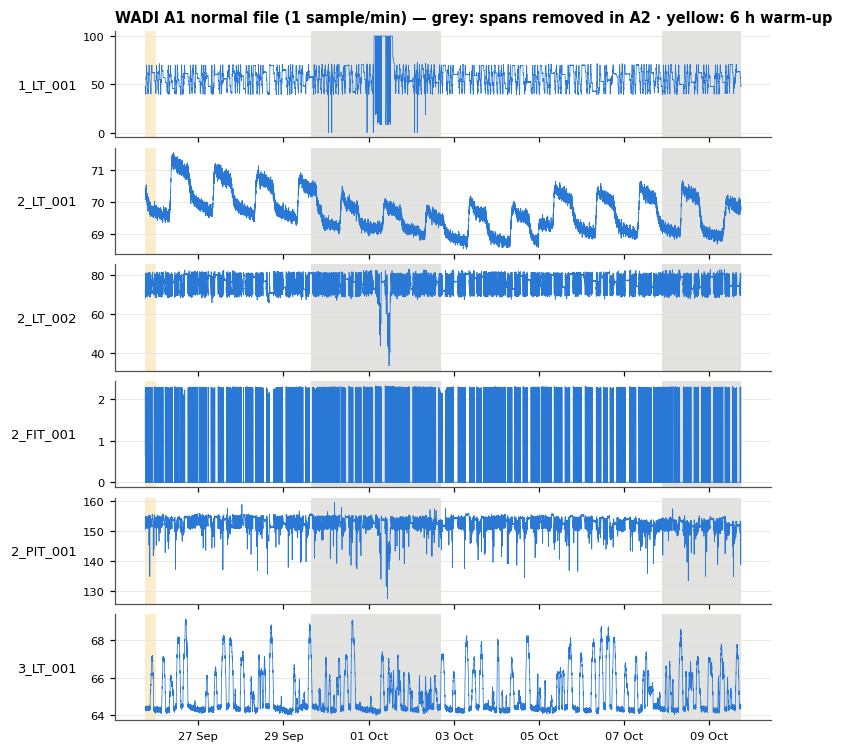

In [7]:
def overview(df, name):
    return {"file": name, "rows": len(df), "start": df.timestamp.min(), "end": df.timestamp.max(),
            "span_days": round((df.timestamp.max() - df.timestamp.min()).total_seconds() / 86400, 2),
            "recording_blocks": int(df.block_id.nunique()), "rows_with_missing": int(df.has_missing.sum())}
display(pd.DataFrame([overview(normal, "normal"), overview(attack, "attack")]))

level_tags = [c for c in ["1_LT_001_PV", "2_LT_001_PV", "2_LT_002_PV", "2_FIT_001_PV", "2_PIT_001_PV", "3_LT_001_PV"] if c in SENSORS] or SENSORS[:4]
sub = normal.iloc[::60]
fig, axes = plt.subplots(len(level_tags), 1, figsize=(7.16, 1.05 * len(level_tags) + 0.6), sharex=True)
for ax, tag in zip(np.atleast_1d(axes), level_tags):
    ax.plot(sub.timestamp, sub[tag], lw=0.5, color=SERIES[0])
    for lo, hi in A2_REMOVED_SPANS:
        ax.axvspan(pd.Timestamp(lo), pd.Timestamp(hi), color=REMOVED_SHADE, alpha=0.25, lw=0)
    ax.axvspan(normal.timestamp.min(), normal.timestamp.min() + pd.Timedelta(seconds=WARMUP_SECONDS), color="#eda100", alpha=0.2, lw=0)
    ax.set_ylabel(tag.replace("_PV", ""), rotation=0, ha="right", va="center")
    ax.grid(axis="x", visible=False)
axes[0].set_title("WADI A1 normal file (1 sample/min) — grey: spans removed in A2 · yellow: 6 h warm-up", loc="left")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
fig.align_ylabels(axes)
plt.tight_layout(h_pad=0.3)
save_fig(fig, "normal_overview")
plt.show()

## 5. Feature summary and constant columns

In [8]:
normal_ok = normal[(normal.is_warmup == 0) & (normal.a2_removed == 0)]
summary = pd.DataFrame({
    "stage": [stage_of(c) for c in FEATURES],
    "kind": ["discrete" if c in DISCRETE else "sensor" for c in FEATURES],
    "normal_mean": normal_ok[FEATURES].mean().values, "normal_std": normal_ok[FEATURES].std().values,
    "normal_min": normal_ok[FEATURES].min().values, "normal_max": normal_ok[FEATURES].max().values,
    "normal_nunique": normal_ok[FEATURES].nunique().values,
    "a1_full_nunique": normal[normal.is_warmup == 0][FEATURES].nunique().values,
    "attack_nunique": attack[FEATURES].nunique().values,
}, index=FEATURES)
CONSTANT_IN_NORMAL = summary.index[summary.a1_full_nunique <= 1].tolist()
print(f"Constant over the whole A1 normal file ({len(CONSTANT_IN_NORMAL)}):", CONSTANT_IN_NORMAL)
print("Constant in the A2-kept normal rows but varying in the A2-removed spans:",
      summary.index[(summary.normal_nunique <= 1) & (summary.a1_full_nunique > 1)].tolist())
print("Constant in normal but varying in the attack file:",
      summary.index[(summary.a1_full_nunique <= 1) & (summary.attack_nunique > 1)].tolist())
summary.round(3)

Constant over the whole A1 normal file (30): ['1_LS_001_AL', '1_LS_002_AL', '1_MV_002_STATUS', '1_MV_003_STATUS', '1_P_002_STATUS', '1_P_004_STATUS', '1_P_006_STATUS', '2_MCV_007_CO', '2_MV_001_STATUS', '2_MV_002_STATUS', '2_MV_004_STATUS', '2_MV_005_STATUS', '2_MV_009_STATUS', '2_P_004_STATUS', '2_PIC_003_SP', '2_SV_101_STATUS', '2_SV_201_STATUS', '2_SV_301_STATUS', '2_SV_401_STATUS', '2_SV_501_STATUS', '2_SV_601_STATUS', '3_LS_001_AL', '3_MV_001_STATUS', '3_MV_002_STATUS', '3_MV_003_STATUS', '3_P_001_STATUS', '3_P_002_STATUS', '3_P_003_STATUS', '3_P_004_STATUS', 'PLANT_START_STOP_LOG']
Constant in the A2-kept normal rows but varying in the A2-removed spans: []
Constant in normal but varying in the attack file: ['1_MV_002_STATUS', '1_MV_003_STATUS', '1_P_006_STATUS', '2_MCV_007_CO', '2_PIC_003_SP']


,stage,kind,normal_mean,normal_std,normal_min,normal_max,normal_nunique,a1_full_nunique,attack_nunique
1_AIT_001_PV,1,sensor,169.845,15.104,0.000,214.311,37517,40479,10941
1_AIT_002_PV,1,sensor,0.622,0.061,0.000,2.059,359,377,202
1_AIT_003_PV,1,sensor,11.702,0.180,0.000,12.013,5587,7185,1989
1_AIT_004_PV,1,sensor,493.587,19.528,0.000,526.529,16000,20017,11325
1_AIT_005_PV,1,sensor,0.310,0.050,0.208,0.422,24045,25601,12427
...,...,...,...,...,...,...,...,...,...
3_P_003_STATUS,3,discrete,1.000,0.000,1.000,1.000,1,1,1
3_P_004_STATUS,3,discrete,1.000,0.000,1.000,1.000,1,1,1
LEAK_DIFF_PRESSURE,0,sensor,63.090,6.038,45.396,144.266,65260,80126,24458
PLANT_START_STOP_LOG,0,discrete,1.000,0.000,1.000,1.000,1,1,1


## 6. Discrete tag states

In [9]:
rows = []
for c in DISCRETE:
    for name, df in [("normal (A1, no warm-up)", normal[normal.is_warmup == 0]), ("attack-file", attack)]:
        vc = df[c].value_counts(normalize=True).round(4)
        rows.append({"tag": c, "file": name, **{f"state_{int(k)}": v for k, v in vc.items()}})
states = pd.DataFrame(rows).set_index(["tag", "file"]).fillna(0).sort_index(axis=1)
normal_states = {c: set(normal.loc[normal.is_warmup == 0, c].dropna().unique()) for c in DISCRETE}
new_states = [c for c in DISCRETE if set(attack[c].dropna().unique()) - normal_states[c]]
print("Discrete tags with a state seen in the attack file but never in the A1 normal file:", new_states)
states

Discrete tags with a state seen in the attack file but never in the A1 normal file: ['1_MV_002_STATUS', '1_MV_003_STATUS', '1_P_006_STATUS']


state_0  state_1  state_2
tag                  file                                              
1_LS_001_AL          normal (A1, no warm-up)    1.000   0.0000   0.0000
                     attack-file                1.000   0.0000   0.0000
1_LS_002_AL          normal (A1, no warm-up)    1.000   0.0000   0.0000
                     attack-file                1.000   0.0000   0.0000
1_MV_001_STATUS      normal (A1, no warm-up)    0.002   0.7249   0.2732
...                                               ...      ...      ...
3_P_003_STATUS       attack-file                0.000   1.0000   0.0000
3_P_004_STATUS       normal (A1, no warm-up)    0.000   1.0000   0.0000
                     attack-file                0.000   1.0000   0.0000
PLANT_START_STOP_LOG normal (A1, no warm-up)    0.000   1.0000   0.0000
                     attack-file                0.000   1.0000   0.0000

[108 rows x 3 columns]

## 7. Official attack table → labels

A1 ships without labels. The table below is transcribed from `attack_description.xlsx` (start/end are Excel day fractions in the file) and cross-checked against it in the next cell. Fixes applied to the file's typos:
- Rows 11–15 are dated `42927` (= 12 Jul 2017) and row 5 `17450`: they are 11 Oct and 10 Oct (the attack file only covers 9–11 Oct, and the times follow the sequence).
- Row 5's start is the text `11.30:40` → 11:30:40.
- The second row numbered `2` (1_AIT_001, 11:07:46 → 11:12:15) is **attack 4**. It lies inside attack 3 (10:55 → 11:24), so the two are one event, `3-4`, as in the A2 labels.
- Attack 7 has two steps (1_AIT_002 from 14:48:17, 2_MV_003 until 15:00:32): the event spans both.
- Attack 13 (2_PIC_003 set point) **is labelled here**. In A2 it has no labelled rows.

A row is labelled `attack` if its timestamp lies inside a listed window (inclusive), the convention of the published WADI A1 benchmarks.

In [10]:
ATTACK_LIST = pd.DataFrame([
    ("1", "2017-10-09 19:25:00", "2017-10-09 19:50:16", "1_MV_001", "Motorised valve 1_MV_001 opened: overflow of the primary tank."),
    ("2", "2017-10-10 10:24:10", "2017-10-10 10:34:00", "1_FIT_001", "False readings on flow transmitter 1_FIT_001: chemical dosing pumps start, no level increase."),
    ("3-4", "2017-10-10 10:55:00", "2017-10-10 11:24:00", "2_LT_002; 1_AIT_001", "Stealthy: elevated reservoir level 70→80% fast, 80→70% slow (drain); 1_AIT_001 spoofed 176→640 (11:07:46–11:12:15)."),
    ("5", "2017-10-10 11:30:40", "2017-10-10 11:44:50", "2_MCV_101..601", "All consumer inlet valves brought to 0%: no water to consumers."),
    ("6", "2017-10-10 13:39:30", "2017-10-10 13:50:40", "2_MCV_101; 2_MCV_201", "Consumer valves 2_MCV_101/201 opened to 50%."),
    ("7", "2017-10-10 14:48:17", "2017-10-10 15:00:32", "1_AIT_002; 2_MV_003", "1_AIT_002 set to 6 (contamination), drain valves open; 2_MV_003 opened (14:53:44–15:00:32): contaminated water to the ER tank."),
    ("8", "2017-10-10 17:40:00", "2017-10-10 17:49:40", "2_MCV_007", "2_MCV_007 opened to 30%: water leakage."),
    ("9", "2017-10-11 10:55:00", "2017-10-11 10:56:27", "1_P_005; 1_P_006", "1_P_005 on and 1_P_006 off→on: pipe burst."),
    ("10", "2017-10-11 11:17:54", "2017-10-11 11:31:20", "1_MV_001", "Randomised attack on 1_MV_001: damage the valve and raw-water pump, ER tank drains."),
    ("11", "2017-10-11 11:36:31", "2017-10-11 11:47:00", "2_MCV_007", "2_MCV_007 set to 50%: booster never turns on."),
    ("12", "2017-10-11 11:59:00", "2017-10-11 12:05:00", "2_MCV_007", "2_MCV_007 opened to 100% in 10% steps: water wasted."),
    ("13", "2017-10-11 12:07:30", "2017-10-11 12:10:52", "2_PIC_003_SP", "Booster pressure set point 1 → 0.25 bar: intermittent supply."),
    ("14", "2017-10-11 12:16:00", "2017-10-11 12:25:36", "1_P_001; 1_P_003", "Chemical dosing pumps off: dosing to the raw-water tank stops."),
    ("15", "2017-10-11 15:26:30", "2017-10-11 15:37:00", "2_LT_002", "Stealthy, inverse of 3: level 70→80% slow, 80→70% fast (ER overflow)."),
], columns=["attack_id", "start", "end", "attack_point", "description"])
ATTACK_LIST["start"] = pd.to_datetime(ATTACK_LIST["start"])
ATTACK_LIST["end"] = pd.to_datetime(ATTACK_LIST["end"])
ATTACK_LIST["duration_s"] = (ATTACK_LIST["end"] - ATTACK_LIST["start"]).dt.total_seconds() + 1
assert ATTACK_LIST["start"].is_monotonic_increasing and (ATTACK_LIST["start"].iloc[1:].to_numpy() > ATTACK_LIST["end"].iloc[:-1].to_numpy()).all()
ATTACK_LIST

,attack_id,start,end,attack_point,description,duration_s
0,1,2017-10-09 19:25:00,2017-10-09 19:50:16,1_MV_001,Motorised valve 1_MV_001 opened: overflow of t...,1517.0
1,2,2017-10-10 10:24:10,2017-10-10 10:34:00,1_FIT_001,False readings on flow transmitter 1_FIT_001: ...,591.0
2,3-4,2017-10-10 10:55:00,2017-10-10 11:24:00,2_LT_002; 1_AIT_001,Stealthy: elevated reservoir level 70→80% fast...,1741.0
3,5,2017-10-10 11:30:40,2017-10-10 11:44:50,2_MCV_101..601,All consumer inlet valves brought to 0%: no wa...,851.0
4,6,2017-10-10 13:39:30,2017-10-10 13:50:40,2_MCV_101; 2_MCV_201,Consumer valves 2_MCV_101/201 opened to 50%.,671.0
5,7,2017-10-10 14:48:17,2017-10-10 15:00:32,1_AIT_002; 2_MV_003,"1_AIT_002 set to 6 (contamination), drain valv...",736.0
6,8,2017-10-10 17:40:00,2017-10-10 17:49:40,2_MCV_007,2_MCV_007 opened to 30%: water leakage.,581.0
7,9,2017-10-11 10:55:00,2017-10-11 10:56:27,1_P_005; 1_P_006,1_P_005 on and 1_P_006 off→on: pipe burst.,88.0
8,10,2017-10-11 11:17:54,2017-10-11 11:31:20,1_MV_001,Randomised attack on 1_MV_001: damage the valv...,807.0
9,11,2017-10-11 11:36:31,2017-10-11 11:47:00,2_MCV_007,2_MCV_007 set to 50%: booster never turns on.,630.0


In [11]:
# Cross-check against attack_description.xlsx with a minimal reader (no openpyxl needed).
NS = "{http://schemas.openxmlformats.org/spreadsheetml/2006/main}"


def read_xlsx_cells(path):
    with zipfile.ZipFile(path) as z:
        shared = []
        if "xl/sharedStrings.xml" in z.namelist():
            root = ET.fromstring(z.read("xl/sharedStrings.xml"))
            shared = ["".join(t.text or "" for t in si.iter(f"{NS}t")) for si in root.iter(f"{NS}si")]
        sheet = ET.fromstring(z.read("xl/worksheets/sheet1.xml"))
    cells = {}
    for c in sheet.iter(f"{NS}c"):
        col, row = re.match(r"([A-Z]+)(\d+)", c.get("r")).groups()
        v = c.find(f"{NS}v")
        if v is not None:
            cells.setdefault(int(row), {})[col] = shared[int(v.text)] if c.get("t") == "s" else v.text
    return cells


def day_fraction_to_time(v):
    try:
        f = float(v)
    except (TypeError, ValueError):
        return None
    if not 0 <= f < 1:
        return None
    s = int(round(f * 86400))
    return f"{s // 3600:02d}:{s % 3600 // 60:02d}:{s % 60:02d}"


if ATTACK_TABLE_FILE.exists():
    xl_rows = []
    for r, cells in sorted(read_xlsx_cells(ATTACK_TABLE_FILE).items()):
        start, end = day_fraction_to_time(cells.get("C")), day_fraction_to_time(cells.get("D"))
        if start or end:
            xl_rows.append({"xlsx_row": r, "S.No": cells.get("A"), "attack_point": (cells.get("E") or "").replace("\n", " "),
                            "start": start or cells.get("C"), "end": end})
    xl = pd.DataFrame(xl_rows)
    xl_times = set(xl["start"]) | set(xl["end"].dropna())
    check = ATTACK_LIST[["attack_id", "start", "end"]].assign(
        start_in_xlsx=lambda d: d["start"].dt.strftime("%H:%M:%S").isin(xl_times),
        end_in_xlsx=lambda d: d["end"].dt.strftime("%H:%M:%S").isin(xl_times))
    display(xl)
    display(check)
    not_found = check[~(check.start_in_xlsx & check.end_in_xlsx)]
    print("Transcribed times not literally in the xlsx (expected only for the documented fixes: 5 start text):")
    display(not_found)
else:
    print("attack_description.xlsx not found: cross-check skipped.")

,xlsx_row,S.No,attack_point,start,end
0,6,1,1MV001,19:25:00,19:50:16
1,7,2,1FIT001,10:24:10,10:34:00
2,8,3,2LIT002,10:55:00,11:24:00
3,9,2,1AIT001,11:07:46,11:12:15
4,10,5,"2MCV101, 2MCV201",11.30:40,11:44:50
5,14,6,"2MCV101, 2MCv201",13:39:30,13:50:40
6,16,7,1_AIT_002,14:48:17,14:59:55
7,17,NaN,2MV003,14:53:44,15:00:32
8,18,8,2MCV007,17:40:00,17:49:40
9,19,9,1-P-005 On and 1-P-006 OFF,10:55:00,10:56:27


,attack_id,start,end,start_in_xlsx,end_in_xlsx
0,1,2017-10-09 19:25:00,2017-10-09 19:50:16,True,True
1,2,2017-10-10 10:24:10,2017-10-10 10:34:00,True,True
2,3-4,2017-10-10 10:55:00,2017-10-10 11:24:00,True,True
3,5,2017-10-10 11:30:40,2017-10-10 11:44:50,False,True
4,6,2017-10-10 13:39:30,2017-10-10 13:50:40,True,True
5,7,2017-10-10 14:48:17,2017-10-10 15:00:32,True,True
6,8,2017-10-10 17:40:00,2017-10-10 17:49:40,True,True
7,9,2017-10-11 10:55:00,2017-10-11 10:56:27,True,True
8,10,2017-10-11 11:17:54,2017-10-11 11:31:20,True,True
9,11,2017-10-11 11:36:31,2017-10-11 11:47:00,True,True


Transcribed times not literally in the xlsx (expected only for the documented fixes: 5 start text):


,attack_id,start,end,start_in_xlsx,end_in_xlsx
3,5,2017-10-10 11:30:40,2017-10-10 11:44:50,False,True


In [12]:
seg_id = np.zeros(len(attack), dtype=np.int16)
attack_id = np.full(len(attack), "", dtype=object)
for i, r in enumerate(ATTACK_LIST.itertuples(), start=1):
    m = attack["timestamp"].between(r.start, r.end).to_numpy()
    seg_id[m] = i
    attack_id[m] = r.attack_id
attack["is_attack"] = (seg_id > 0).astype("int8")
attack["segment_id"] = seg_id
attack["attack_id"] = pd.Series(attack_id, index=attack.index).replace("", pd.NA).astype("string")
attack["label"] = np.where(attack["is_attack"] == 1, "attack", "normal")
normal["is_attack"] = np.int8(0)
normal["label"] = "normal"


def label_segments(df):
    a = df.is_attack.to_numpy()
    edges = np.diff(np.r_[0, a, 0])
    starts, ends = np.where(edges == 1)[0], np.where(edges == -1)[0] - 1
    seg = pd.DataFrame({"segment": np.arange(1, len(starts) + 1),
                        "start": df.timestamp.to_numpy()[starts], "end": df.timestamp.to_numpy()[ends],
                        "n_rows": ends - starts + 1})
    seg["duration_s"] = (seg.end - seg.start).dt.total_seconds() + 1
    seg["attack_id"] = df["attack_id"].to_numpy()[starts]
    return seg


segments = label_segments(attack).merge(ATTACK_LIST[["attack_id", "attack_point", "description"]], on="attack_id", how="left")
assert len(segments) == len(ATTACK_LIST), "every listed attack must give exactly one contiguous segment"
print(f"{len(segments)} attack segments | {int(attack.is_attack.sum()):,} attack rows ({attack.is_attack.mean():.2%}) | "
      f"median {segments.duration_s.median():.0f} s, max {segments.duration_s.max():.0f} s")
segments

14 attack segments | 9,985 attack rows (5.78%) | median 630 s, max 1741 s


,segment,start,end,n_rows,duration_s,attack_id,attack_point,description
0,1,2017-10-09 19:25:00,2017-10-09 19:50:16,1517,1517.0,1,1_MV_001,Motorised valve 1_MV_001 opened: overflow of t...
1,2,2017-10-10 10:24:10,2017-10-10 10:34:00,591,591.0,2,1_FIT_001,False readings on flow transmitter 1_FIT_001: ...
2,3,2017-10-10 10:55:00,2017-10-10 11:24:00,1741,1741.0,3-4,2_LT_002; 1_AIT_001,Stealthy: elevated reservoir level 70→80% fast...
3,4,2017-10-10 11:30:40,2017-10-10 11:44:50,851,851.0,5,2_MCV_101..601,All consumer inlet valves brought to 0%: no wa...
4,5,2017-10-10 13:39:30,2017-10-10 13:50:40,671,671.0,6,2_MCV_101; 2_MCV_201,Consumer valves 2_MCV_101/201 opened to 50%.
5,6,2017-10-10 14:48:17,2017-10-10 15:00:32,736,736.0,7,1_AIT_002; 2_MV_003,"1_AIT_002 set to 6 (contamination), drain valv..."
6,7,2017-10-10 17:40:00,2017-10-10 17:49:40,581,581.0,8,2_MCV_007,2_MCV_007 opened to 30%: water leakage.
7,8,2017-10-11 10:55:00,2017-10-11 10:56:27,88,88.0,9,1_P_005; 1_P_006,1_P_005 on and 1_P_006 off→on: pipe burst.
8,9,2017-10-11 11:17:54,2017-10-11 11:31:20,807,807.0,10,1_MV_001,Randomised attack on 1_MV_001: damage the valv...
9,10,2017-10-11 11:36:31,2017-10-11 11:47:00,630,630.0,11,2_MCV_007,2_MCV_007 set to 50%: booster never turns on.


## 8. A1 vs. A2: same data, different normal span and labels

A2 normal rows found in A1: 784,571 of 784,571 | A1 rows removed in A2: 425,029
Share of identical values on probe tags: {'1_LT_001_PV': 1.0, '2_LT_002_PV': 1.0, '2_FIT_001_PV': 0.99789, '1_AIT_001_PV': 1.0, '2_PIT_001_PV': 1.0}
a2_removed flag agrees with the A2 file: True


,min,max,size,hours
timestamp,,,,
1,2017-09-29 15:19:59,2017-10-02 16:39:58,264000,73.333333
2,2017-10-07 21:16:11,2017-10-09 17:59:59,161029,44.730278


Attack file: identical values on 99.9968% of 123 common tags × 172,801 rows


A2 (label column),0,1
A1 (table),,
0,162538,278
1,286,9699


figure saved: output-figures/labels_a1_vs_a2_wadi2017.png


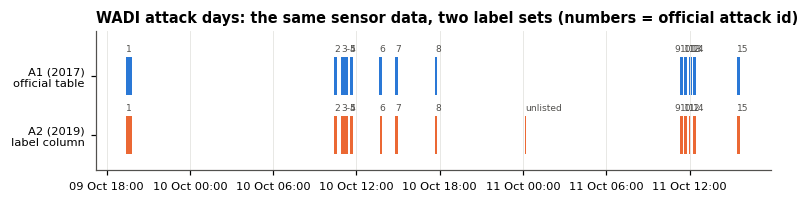

In [13]:
a2_files = {k: A2_CLEAN_DIR / f"wadi2019_{k}_clean.csv" for k in ["normal", "attack"]}
A2_COMPARISON = {}
if all(p.exists() for p in a2_files.values()):
    probe = [c for c in ["1_LT_001_PV", "2_LT_002_PV", "2_FIT_001_PV", "1_AIT_001_PV", "2_PIT_001_PV"] if c in SENSORS]
    a2n = pd.read_csv(a2_files["normal"], usecols=["timestamp"] + probe, parse_dates=["timestamp"])
    a2a = pd.read_csv(A2_CLEAN_DIR / "wadi2019_attack_clean.csv", parse_dates=["timestamp"], dtype={"attack_id": "string"})

    # Normal file: A2 rows are a subset of A1 rows, with identical values.
    kept = normal["timestamp"].isin(a2n["timestamp"]).to_numpy()
    joined = normal[["timestamp"] + probe].merge(a2n, on="timestamp", suffixes=("_a1", "_a2"))
    value_match = {c: float(np.isclose(joined[f"{c}_a1"], joined[f"{c}_a2"], equal_nan=True).mean()) for c in probe}
    flag_agrees = bool(((normal["a2_removed"].to_numpy() == 0) == kept).all())
    removed = normal.loc[~kept, "timestamp"]
    spans = removed.groupby((removed.diff().dt.total_seconds() != 1).cumsum()).agg(["min", "max", "size"])
    spans["hours"] = spans["size"] / 3600
    print(f"A2 normal rows found in A1: {int(kept.sum()):,} of {len(a2n):,} | A1 rows removed in A2: {int((~kept).sum()):,}")
    print("Share of identical values on probe tags:", {k: round(v, 5) for k, v in value_match.items()})
    print("a2_removed flag agrees with the A2 file:", flag_agrees)
    display(spans)

    # Attack file: same sensor values; compare the table-derived A1 labels with A2's label column.
    common = [c for c in FEATURES if c in a2a.columns]
    same_values = float(np.isclose(attack[common].to_numpy(float), a2a[common].to_numpy(float), equal_nan=True).mean())
    agree = pd.crosstab(pd.Series(attack["is_attack"].to_numpy(), name="A1 (table)"),
                        pd.Series(a2a["is_attack"].to_numpy(), name="A2 (label column)"))
    print(f"Attack file: identical values on {same_values:.4%} of {len(common)} common tags × {len(attack):,} rows")
    display(agree)
    A2_COMPARISON = {"a2_normal_rows_in_a1": int(kept.sum()), "a1_rows_removed_in_a2": int((~kept).sum()),
                     "removed_spans": [{"start": str(r["min"]), "end": str(r["max"]), "hours": round(r["hours"], 2)} for _, r in spans.iterrows()],
                     "attack_values_identical_share": same_values, "label_agreement": agree.to_dict(),
                     "a2_removed_flag_matches_a2": flag_agrees}

    # Paper figure: label timelines of the attack days, A1 table vs. A2 label column.
    a2_seg = pd.read_csv(A2_CLEAN_DIR / "wadi2019_label_segments.csv", parse_dates=["start", "end"], dtype={"attack_id": str})
    fig, ax = plt.subplots(figsize=(7.16, 1.9))
    for y, segs, color, name in [(1, segments, SERIES[0], "A1 (2017): official table"), (0, a2_seg, SERIES[1], "A2 (2019): label column")]:
        for s in segs.itertuples(index=False):
            ax.broken_barh([(mdates.date2num(s.start), mdates.date2num(s.end) - mdates.date2num(s.start))], (y - 0.32, 0.64),
                           facecolors=color, edgecolor="none")
            ax.text(mdates.date2num(s.start), y + 0.38, str(s.attack_id), fontsize=6, color=MUTED, ha="left", va="bottom")
    ax.set_yticks([1, 0])
    ax.set_yticklabels(["A1 (2017)\nofficial table", "A2 (2019)\nlabel column"])
    ax.set_ylim(-0.6, 1.75)
    ax.xaxis_date()
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b %H:%M"))
    ax.grid(axis="y", visible=False)
    ax.set_title("WADI attack days: the same sensor data, two label sets (numbers = official attack id)", loc="left")
    plt.tight_layout()
    save_fig(fig, "labels_a1_vs_a2")
    plt.show()
else:
    print("A2 clean files not found: comparison skipped (run WADI_A2_2019_EDA_and_cleaning.ipynb to enable it).")

## 9. Attack days overview

figure saved: output-figures/attack_overview_wadi2017.png


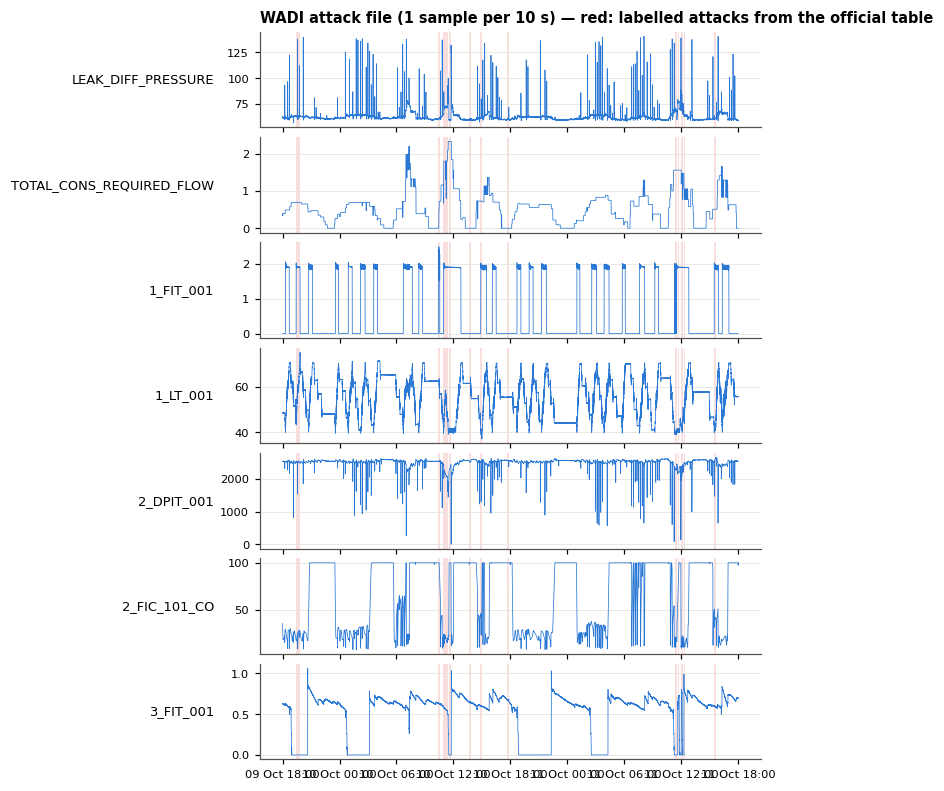

figure saved: output-figures/attack_durations_wadi2017.png


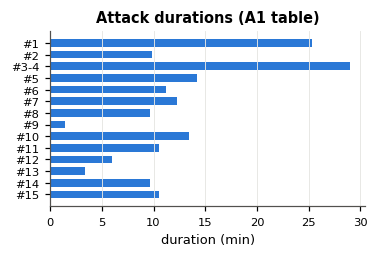

In [14]:
per_stage = []
for st in sorted({stage_of(c) for c in SENSORS}):
    per_stage += [c for c in SENSORS if stage_of(c) == st and c not in CONSTANT_IN_NORMAL and "AIT" not in c][:2]
show = per_stage[:7]
sub = attack.iloc[::10]
fig, axes = plt.subplots(len(show), 1, figsize=(7.16, 0.95 * len(show) + 0.6), sharex=True)
for ax, tag in zip(np.atleast_1d(axes), show):
    ax.plot(sub.timestamp, sub[tag], lw=0.5, color=SERIES[0])
    for s in segments.itertuples():
        ax.axvspan(s.start, s.end, color=ATTACK_SHADE, alpha=0.18, lw=0)
    ax.set_ylabel(tag.replace("_PV", ""), rotation=0, ha="right", va="center")
    ax.grid(axis="x", visible=False)
axes[0].set_title("WADI attack file (1 sample per 10 s) — red: labelled attacks from the official table", loc="left")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b %H:%M"))
fig.align_ylabels(axes)
plt.tight_layout(h_pad=0.3)
save_fig(fig, "attack_overview")
plt.show()

fig, ax = plt.subplots(figsize=(3.5, 2.4))
ax.barh([f"#{a}" for a in segments.attack_id][::-1], (segments.duration_s / 60)[::-1], color=SERIES[0], height=0.65)
ax.set(xlabel="duration (min)", title="Attack durations (A1 table)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
save_fig(fig, "attack_durations")
plt.show()

## 10. Drift, and what makes the A2-removed spans different

Two KS comparisons per sensor (0 = same distribution, 1 = no overlap):
- **attack-file normal rows vs. A2-kept normal rows**: the drift every detector faces at test time;
- **A2-removed spans vs. A2-kept normal rows**: why A2 dropped them. Large values mean the literature protocol (training on all 14 days) puts unusual operation into "normal".

figure saved: output-figures/drift_ks_wadi2017.png


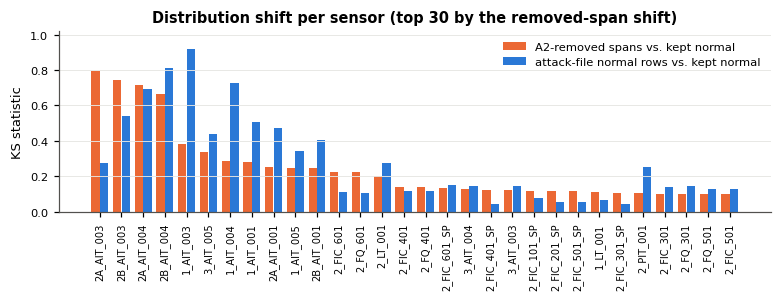

Sensors with KS > 0.5 — removed vs. kept: 4 | attack-file vs. kept: 7 (of 67)


,ks_attack_file_vs_kept,ks_removed_vs_kept,kept_mean,removed_mean,attack_file_normal_mean
2A_AIT_003_PV,0.277,0.794,8.562,8.722,8.615
2B_AIT_003_PV,0.539,0.744,8.523,8.695,8.608
2A_AIT_004_PV,0.691,0.718,486.949,476.301,476.530
2B_AIT_004_PV,0.811,0.668,491.358,480.598,478.197
1_AIT_003_PV,0.918,0.382,11.702,11.850,11.927
3_AIT_005_PV,0.439,0.338,0.679,0.683,0.654
1_AIT_004_PV,0.730,0.288,493.587,476.779,454.181
1_AIT_001_PV,0.506,0.282,169.845,163.595,175.482
2A_AIT_001_PV,0.473,0.251,0.173,0.168,0.179
1_AIT_005_PV,0.340,0.247,0.310,0.285,0.275


In [15]:
rng = np.random.default_rng(RANDOM_STATE)


def sample(x, n=50_000):
    x = x.dropna().values
    return x if len(x) <= n else rng.choice(x, n, replace=False)


ks_tags = [c for c in SENSORS if c not in CONSTANT_IN_NORMAL]
kept_rows = normal[(normal.is_warmup == 0) & (normal.a2_removed == 0)]
removed_rows = normal[normal.a2_removed == 1]
attack_normal_rows = attack[attack.is_attack == 0]
ks = pd.DataFrame({
    "ks_attack_file_vs_kept": [ks_2samp(sample(kept_rows[c]), sample(attack_normal_rows[c])).statistic for c in ks_tags],
    "ks_removed_vs_kept": [ks_2samp(sample(kept_rows[c]), sample(removed_rows[c])).statistic for c in ks_tags],
    "kept_mean": kept_rows[ks_tags].mean().values, "removed_mean": removed_rows[ks_tags].mean().values,
    "attack_file_normal_mean": attack_normal_rows[ks_tags].mean().values,
}, index=ks_tags).sort_values("ks_removed_vs_kept", ascending=False)

top = ks.head(30)
fig, ax = plt.subplots(figsize=(7.16, 2.8))
x = np.arange(len(top))
ax.bar(x - 0.2, top.ks_removed_vs_kept, 0.38, color=SERIES[1], label="A2-removed spans vs. kept normal")
ax.bar(x + 0.2, top.ks_attack_file_vs_kept, 0.38, color=SERIES[0], label="attack-file normal rows vs. kept normal")
ax.set_xticks(x)
ax.set_xticklabels([t.replace("_PV", "") for t in top.index], rotation=90, fontsize=6.5)
ax.set(ylabel="KS statistic", ylim=(0, 1.02), title="Distribution shift per sensor (top 30 by the removed-span shift)")
ax.legend(loc="upper right", frameon=False)
ax.grid(axis="x", visible=False)
plt.tight_layout()
save_fig(fig, "drift_ks")
plt.show()
print(f"Sensors with KS > 0.5 — removed vs. kept: {int((ks.ks_removed_vs_kept > 0.5).sum())} | "
      f"attack-file vs. kept: {int((ks.ks_attack_file_vs_kept > 0.5).sum())} (of {len(ks)})")
ks.round(3).head(20)

## 11. Sensor correlations in normal operation

figure saved: output-figures/sensor_correlation_wadi2017.png


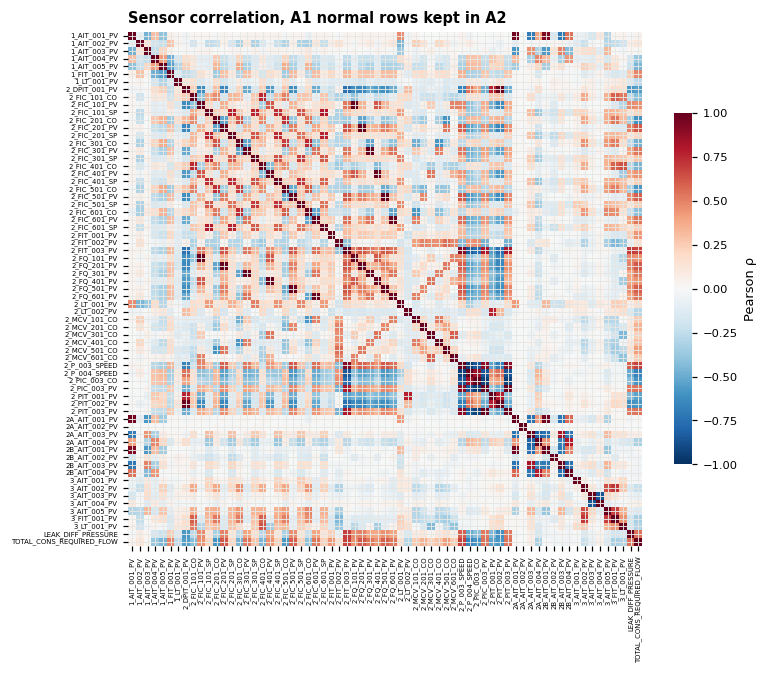

Sensor pairs with |Pearson| ≥ 0.98 (the modelling notebooks remove these with a FIT-only rule):


,,abs_corr
2_FIC_501_PV,2_FQ_501_PV,0.9994
2_PIC_003_PV,2_PIT_003_PV,0.9993
2_FIC_601_PV,2_FQ_601_PV,0.9992
2_FIC_201_PV,2_FQ_201_PV,0.9992
2_FIC_401_PV,2_FQ_401_PV,0.9992
2_FIC_301_PV,2_FQ_301_PV,0.9991
2_FIC_101_PV,2_FQ_101_PV,0.9990
2_DPIT_001_PV,2_PIT_002_PV,0.9870


In [16]:
corr = kept_rows[ks_tags].iloc[::20].corr()
fig, ax = plt.subplots(figsize=(7.16, 6.4))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, ax=ax, xticklabels=True, yticklabels=True,
            cbar_kws={"shrink": 0.6, "label": "Pearson ρ"})
ax.tick_params(labelsize=4.5)
ax.set_title("Sensor correlation, A1 normal rows kept in A2", loc="left")
plt.tight_layout()
save_fig(fig, "sensor_correlation")
plt.show()
upper = corr.abs().where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
dup_pairs = upper.stack().loc[lambda s: s >= 0.98].sort_values(ascending=False)
print("Sensor pairs with |Pearson| ≥ 0.98 (the modelling notebooks remove these with a FIT-only rule):")
display(dup_pairs.rename("abs_corr").round(4).to_frame())

## 12. Save the clean files

In [17]:
t0 = time.time()
normal_cols = ["timestamp"] + FEATURES + ["label", "is_attack", "is_warmup", "a2_removed", "has_missing", "block_id"]
attack_cols = ["timestamp"] + FEATURES + ["label", "is_attack", "attack_id", "segment_id", "has_missing", "block_id"]
paths = {
    "normal": OUT_DIR / "wadi2017_normal_clean.csv",
    "attack": OUT_DIR / "wadi2017_attack_clean.csv",
    "segments": OUT_DIR / "wadi2017_label_segments.csv",
    "attack_list": OUT_DIR / "wadi2017_attack_list_clean.csv",
    "metadata": OUT_DIR / "wadi2017_metadata.json",
}
TS_FMT = "%Y-%m-%d %H:%M:%S"
normal[normal_cols].to_csv(paths["normal"], index=False, date_format=TS_FMT)
attack[attack_cols].to_csv(paths["attack"], index=False, date_format=TS_FMT)
segments.to_csv(paths["segments"], index=False, date_format=TS_FMT)
ATTACK_LIST.to_csv(paths["attack_list"], index=False, date_format=TS_FMT)

stages = sorted({stage_of(c) for c in FEATURES})
metadata = {
    "dataset": "WADI A1 (9 Oct 2017)",
    "release": "A1",
    "cleaning_version": 2,               # same file format as WADI A2 cleaning v2 (modelling notebooks check this)
    "source_files": {"normal": NORMAL_FILE.name, "attack": ATTACK_FILE.name, "attack_list": ATTACK_TABLE_FILE.name + " (transcribed, cross-checked)"},
    "sampling_period_s": 1,
    "timestamp_note": "parsed from Date + Time (full h:mm:ss AM/PM) and verified against the 1 Hz Row counter for every row; "
                      "the normal file's last row (= first attack row, 9 Oct 18:00:00) was dropped",
    "label_note": "A1 has no label column: is_attack = 1 inside the official attack windows (inclusive). Attacks 3 and 4 form one event (3-4).",
    "features": FEATURES, "sensors": SENSORS,
    "actuators": DISCRETE,               # same key as the SWaT / WADI A2 metadata, for shared code
    "discrete_tags": DISCRETE,
    "stages": {str(s): [c for c in FEATURES if stage_of(c) == s] for s in stages},
    "stage_note": "stage 0 = plant-wide tags without a numeric stage prefix (incl. 2A_/2B_ analysers)",
    "dropped_empty_columns": EMPTY_COLS,
    "constant_in_normal": CONSTANT_IN_NORMAL,
    "warmup_seconds": WARMUP_SECONDS, "warmup_rows": int(normal.is_warmup.sum()),
    "a2_removed_spans": A2_REMOVED_SPANS, "a2_removed_rows": int(normal.a2_removed.sum()),
    "ffill_limit_s": FFILL_LIMIT,
    "label_encoding": {"is_attack": "1 = attack, 0 = normal (derived from the official attack table)"},
    "cleaning_report": {"normal": rep_normal, "attack": rep_attack},
    "n_label_segments": len(segments),
    "listed_attacks_without_labels": [],
    "a1_vs_a2": A2_COMPARISON,
    "drift_ks_attack_file_top10": ks.ks_attack_file_vs_kept.sort_values(ascending=False).head(10).round(4).to_dict(),
    "drift_ks_removed_spans_top10": ks.ks_removed_vs_kept.head(10).round(4).to_dict(),
}
paths["metadata"].write_text(json.dumps(metadata, indent=2, default=str))
for k, p in paths.items():
    print(f"{k:12s} {p}  ({p.stat().st_size / 1e6:.1f} MB)")
print(f"Saved in {time.time() - t0:.0f} s")

normal       scada-data/WaDI/WaDi/WaDi.A1_9-Oct-2017/clean/wadi2017_normal_clean.csv  (802.4 MB)
attack       scada-data/WaDI/WaDi/WaDi.A1_9-Oct-2017/clean/wadi2017_attack_clean.csv  (114.6 MB)
segments     scada-data/WaDI/WaDi/WaDi.A1_9-Oct-2017/clean/wadi2017_label_segments.csv  (0.0 MB)
attack_list  scada-data/WaDI/WaDi/WaDi.A1_9-Oct-2017/clean/wadi2017_attack_list_clean.csv  (0.0 MB)
metadata     scada-data/WaDI/WaDi/WaDi.A1_9-Oct-2017/clean/wadi2017_metadata.json  (0.0 MB)
Saved in 38 s


## 13. Reload check and how to use the files

In [18]:
chk_n = pd.read_csv(paths["normal"], parse_dates=["timestamp"])
chk_a = pd.read_csv(paths["attack"], parse_dates=["timestamp"], dtype={"attack_id": "string"})
assert len(chk_n) == len(normal) and len(chk_a) == len(attack)
assert np.allclose(chk_n[SENSORS].values, normal[SENSORS].values, equal_nan=True)
assert chk_a.is_attack.sum() == attack.is_attack.sum()
assert chk_n.timestamp.is_monotonic_increasing and chk_a.timestamp.is_monotonic_increasing
assert chk_n.timestamp.max() < chk_a.timestamp.min()
print("Reload OK:", chk_n.shape, chk_a.shape, f"| normal blocks {chk_n.block_id.nunique()} | attack segments {len(segments)}")

Reload OK: (1209600, 130) (172801, 130) | normal blocks 1 | attack segments 14


Loading in the modelling notebooks (same pattern as WADI A2 and SWaT):

```python
import json, pandas as pd
CLEAN = "scada-data/WaDI/WaDi/WaDi.A1_9-Oct-2017/clean"
meta = json.load(open(f"{CLEAN}/wadi2017_metadata.json"))
normal = pd.read_csv(f"{CLEAN}/wadi2017_normal_clean.csv", parse_dates=["timestamp"])
attack = pd.read_csv(f"{CLEAN}/wadi2017_attack_clean.csv", parse_dates=["timestamp"], dtype={"attack_id": "string"})
segments = pd.read_csv(f"{CLEAN}/wadi2017_label_segments.csv", parse_dates=["start", "end"], dtype={"attack_id": str})
train = normal[normal.is_warmup == 0]                      # literature protocol: all 14 days
train_a2_like = train[train.a2_removed == 0]               # A2-like: without the unstable spans
```

- The normal file ends 1 s before the attack file starts, so the two can be concatenated into one continuous 1 Hz stream (as for SWaT).
- Dropping `a2_removed` rows creates gaps: compute rolling features **per contiguous block** after filtering.

## **Conclusions**

**Files and cleaning**
- **Raw files.**
  - `WADI_14days.csv`: 1,209,601 rows at 1 Hz, 25 Sep 18:00 → 9 Oct 18:00 2017, after a 4-line preamble.
  - `WADI_attackdata.csv`: 172,801 rows, 9 Oct 18:00 → 11 Oct 18:00, with **no label column**.
  - Timestamps parse with 0 failures and agree with the `Row` counter everywhere.
- **Overlap.** One row (9 Oct 18:00:00) appears in both files with identical values and was dropped from the normal file.
- **Tags.**
  - 4 columns are completely empty and were dropped (`2_LS_001_AL`, `2_LS_002_AL`, `2_P_001_STATUS`, `2_P_002_STATUS`). That leaves **123 tags: 69 continuous sensors and 54 discrete tags**.
  - Only 50 cells are missing; 15 rows are still missing after the 5 s forward-fill.
- **Constant and attack-only states.**
  - 30 tags are constant over the whole normal file.
  - **5 tags vary only in the attack file:** `1_MV_002_STATUS`, `1_MV_003_STATUS`, `1_P_006_STATUS` (states never seen in normal), `2_MCV_007_CO` and `2_PIC_003_SP`.
  - Several of these are the attack points themselves: attacks 8/11/12 target 2_MCV_007, 13 targets 2_PIC_003, and 9 targets 1_P_006. A trivial "unseen state" rule therefore catches some attacks. This must be reported as a baseline or diagnostic, not hidden inside a learned detector.

**Labels**
- A1 has no label column. The labels come from the official attack table: **14 segments, 9,985 attack rows (5.78%), median duration 630 s**, with attacks 3 and 4 merged because they overlap.
- Every transcribed time matches `attack_description.xlsx` except the start of attack 5, which the xlsx stores as the malformed text "11.30:40".
- **A1 against A2 labels:**
  - 9,699 rows agree.
  - 286 rows are attack only in A1: attack 13 (absent from A2) and onset edges.
  - 278 rows are attack only in A2: the unlisted 00:07 event and onsets shifted by about 3 s.

**A1 against A2 data**
- **Same data.** All 784,571 normal rows of A2 appear in A1 with identical values, and the attack files are 99.997% identical.
- **What A2 removed:** 425,029 rows (35.1% of normal) in two spans, 29 Sep 15:20 → 2 Oct 16:40 (73.3 h) and 7 Oct 21:16 → 9 Oct 18:00 (44.7 h).
- **What differs in those spans:** mostly the water-quality analysers (2A/2B_AIT_003/004, KS 0.67–0.79 against the kept rows).
- **Drift into the attack days:** the normal rows of the attack file have drifted further, for example 1_AIT_003 (KS 0.92), 2B_AIT_004 (0.81) and 1_AIT_004 (0.73). This supports excluding the AIT analysers from the detector inputs, as all modelling notebooks do.
- **Redundant pairs:** 8 sensor pairs have |r| ≥ 0.98 (FIC/FQ duplicates and PIC/PIT). The modelling notebooks remove them with a FIT-only rule.

**Outputs.** The clean files are in `scada-data/WaDI/WaDi/WaDi.A1_9-Oct-2017/clean/` (`wadi2017_*`, `cleaning_version` 2). They carry the `is_warmup`, `a2_removed` and `block_id` flags, so A1-literature and A2-like protocols can both be built from them.

**Implications**
- **A1 is not an independent dataset.** Use it only as the literature anchor, and never pool it with A2.
- **The A2-removed spans must not be used for calibration.** `WADI_A1_2017-baselines` shows that including them in CAL inflates the thresholds of GDN, TranAD and GMM until they raise no alarms.